# Premier League: class final project

This executed review notebook reads the saved experiment. Run the README commands to reproduce training and locked test evaluation. It never calls the original API or opens legacy pickles.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
assert (ROOT/'reports/test_metrics.csv').exists(), 'Run from repository root after the analysis'
R=ROOT/'reports'

## Premier League prediction: final results

Research question: can a random forest beat multinomial logistic regression on home/draw/away probabilities from pre-match team history?

The model selected before opening the test season was **logistic_refined_C0.01**. Its held-out accuracy is **56.5%**, with log loss **0.9472**. Random forest test accuracy is **56.2%**, with log loss **0.9667**. Lower log loss is better. These are observed comparisons on one archived season, not proof of universal superiority.

There is no promise of a particular grade or live forecasting accuracy. The contribution is an auditable, leakage-controlled supervised-learning experiment.

## Data and exact cleaning decisions

The source is TheSportsDB data already saved in the team's original Premier League notebook. No API key or database is required. The saved retrieval timestamp is unknown. We extracted 1,520 scheduled events, excluded 161 unfinished events and 219 completed events from the incomplete 2024–25 season. The three complete seasons contain 1,140 matches.

Five prior recorded matches are required for both teams. This excludes 75 warm-up rows from modeling while retaining them in team histories: 695 development rows (2021–22/2022–23) and 370 held-out rows (2023–24). This means the results do not cover every promoted-team fixture. No mean imputation or outlier deletion was needed for these selected inputs. Optional API statistics were not used. Valid extreme scorelines remain; every exclusion and flagged scoreline is recorded in CSV.

The original notebook added the current result before calculating a last-five feature. Our replacement constructs every match's inputs before adding that day's results. A test changes all current/future scores and confirms earlier/current predictors stay unchanged.

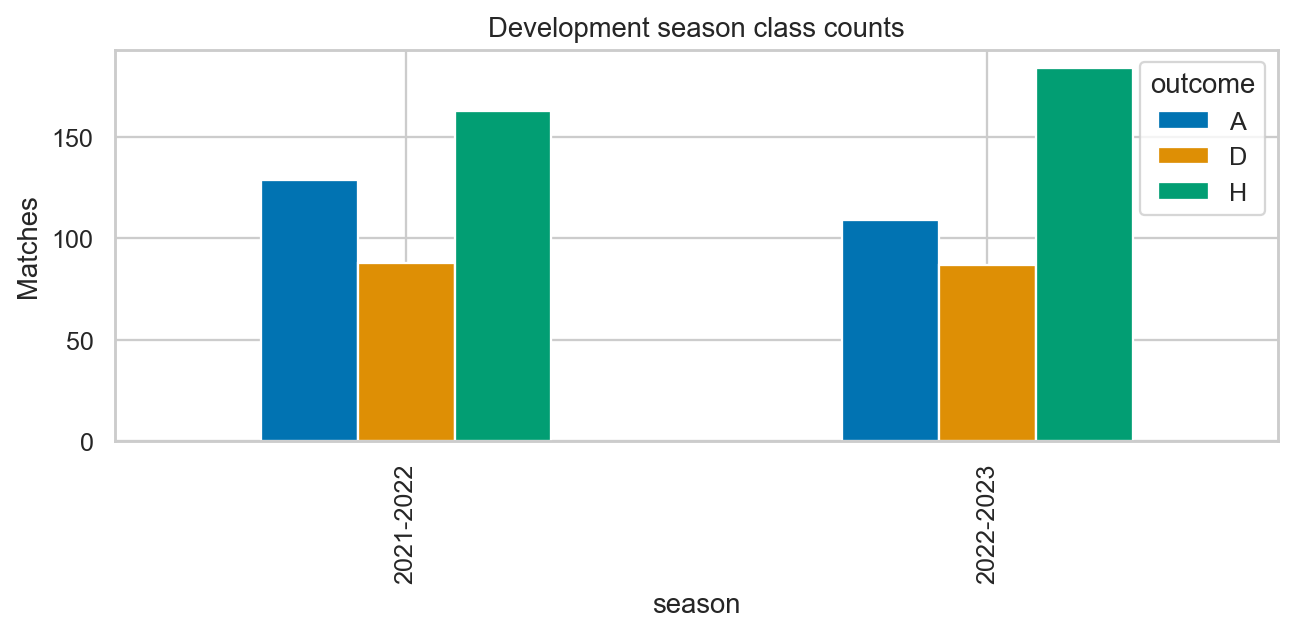

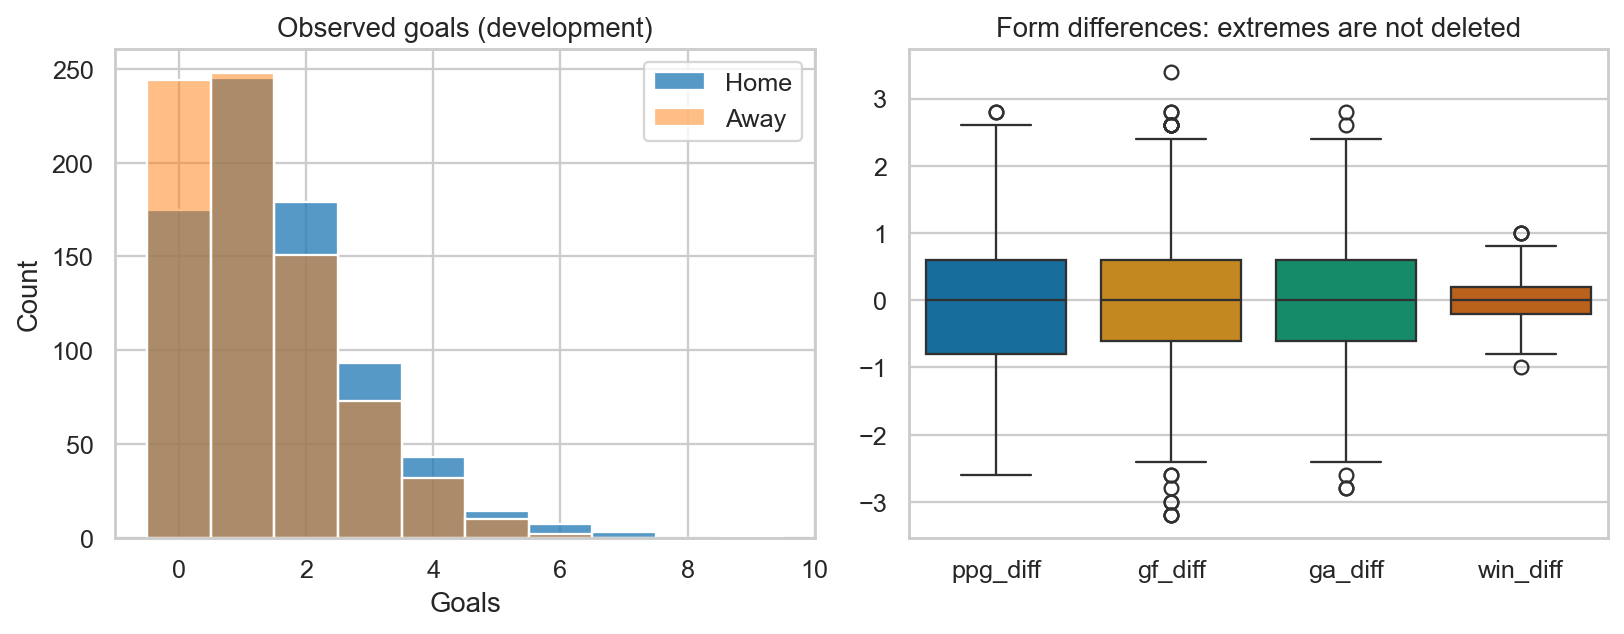

In [2]:
display(Image(filename=str(R/'figures/01_class_counts.png')))
display(Image(filename=str(R/'figures/02_distributions.png')))

## Features and collinearity

We begin with home/away five-game points, goals for, goals against, goal difference, win fraction, capped rest days and prior Elo difference. Elo is a supplemental team-strength feature, not claimed as a taught model. Its constants were fixed and a no-Elo comparison is included.

The full heatmap shows points and wins are strongly correlated. More importantly, goal difference equals goals for minus goals against: full-model VIFs are infinite. Pairwise correlation alone would miss this exact multivariable dependency.

Refinement removes goal difference, uses home-minus-away differences, and iteratively removes predictors with VIF above 5 using only each training fold. The final logistic features are goals-for difference, goals-against difference, win-fraction difference, rest difference and Elo difference. Final VIFs range from about 1.00 to 3.51. This improves interpretability without claiming independent or causal predictors.

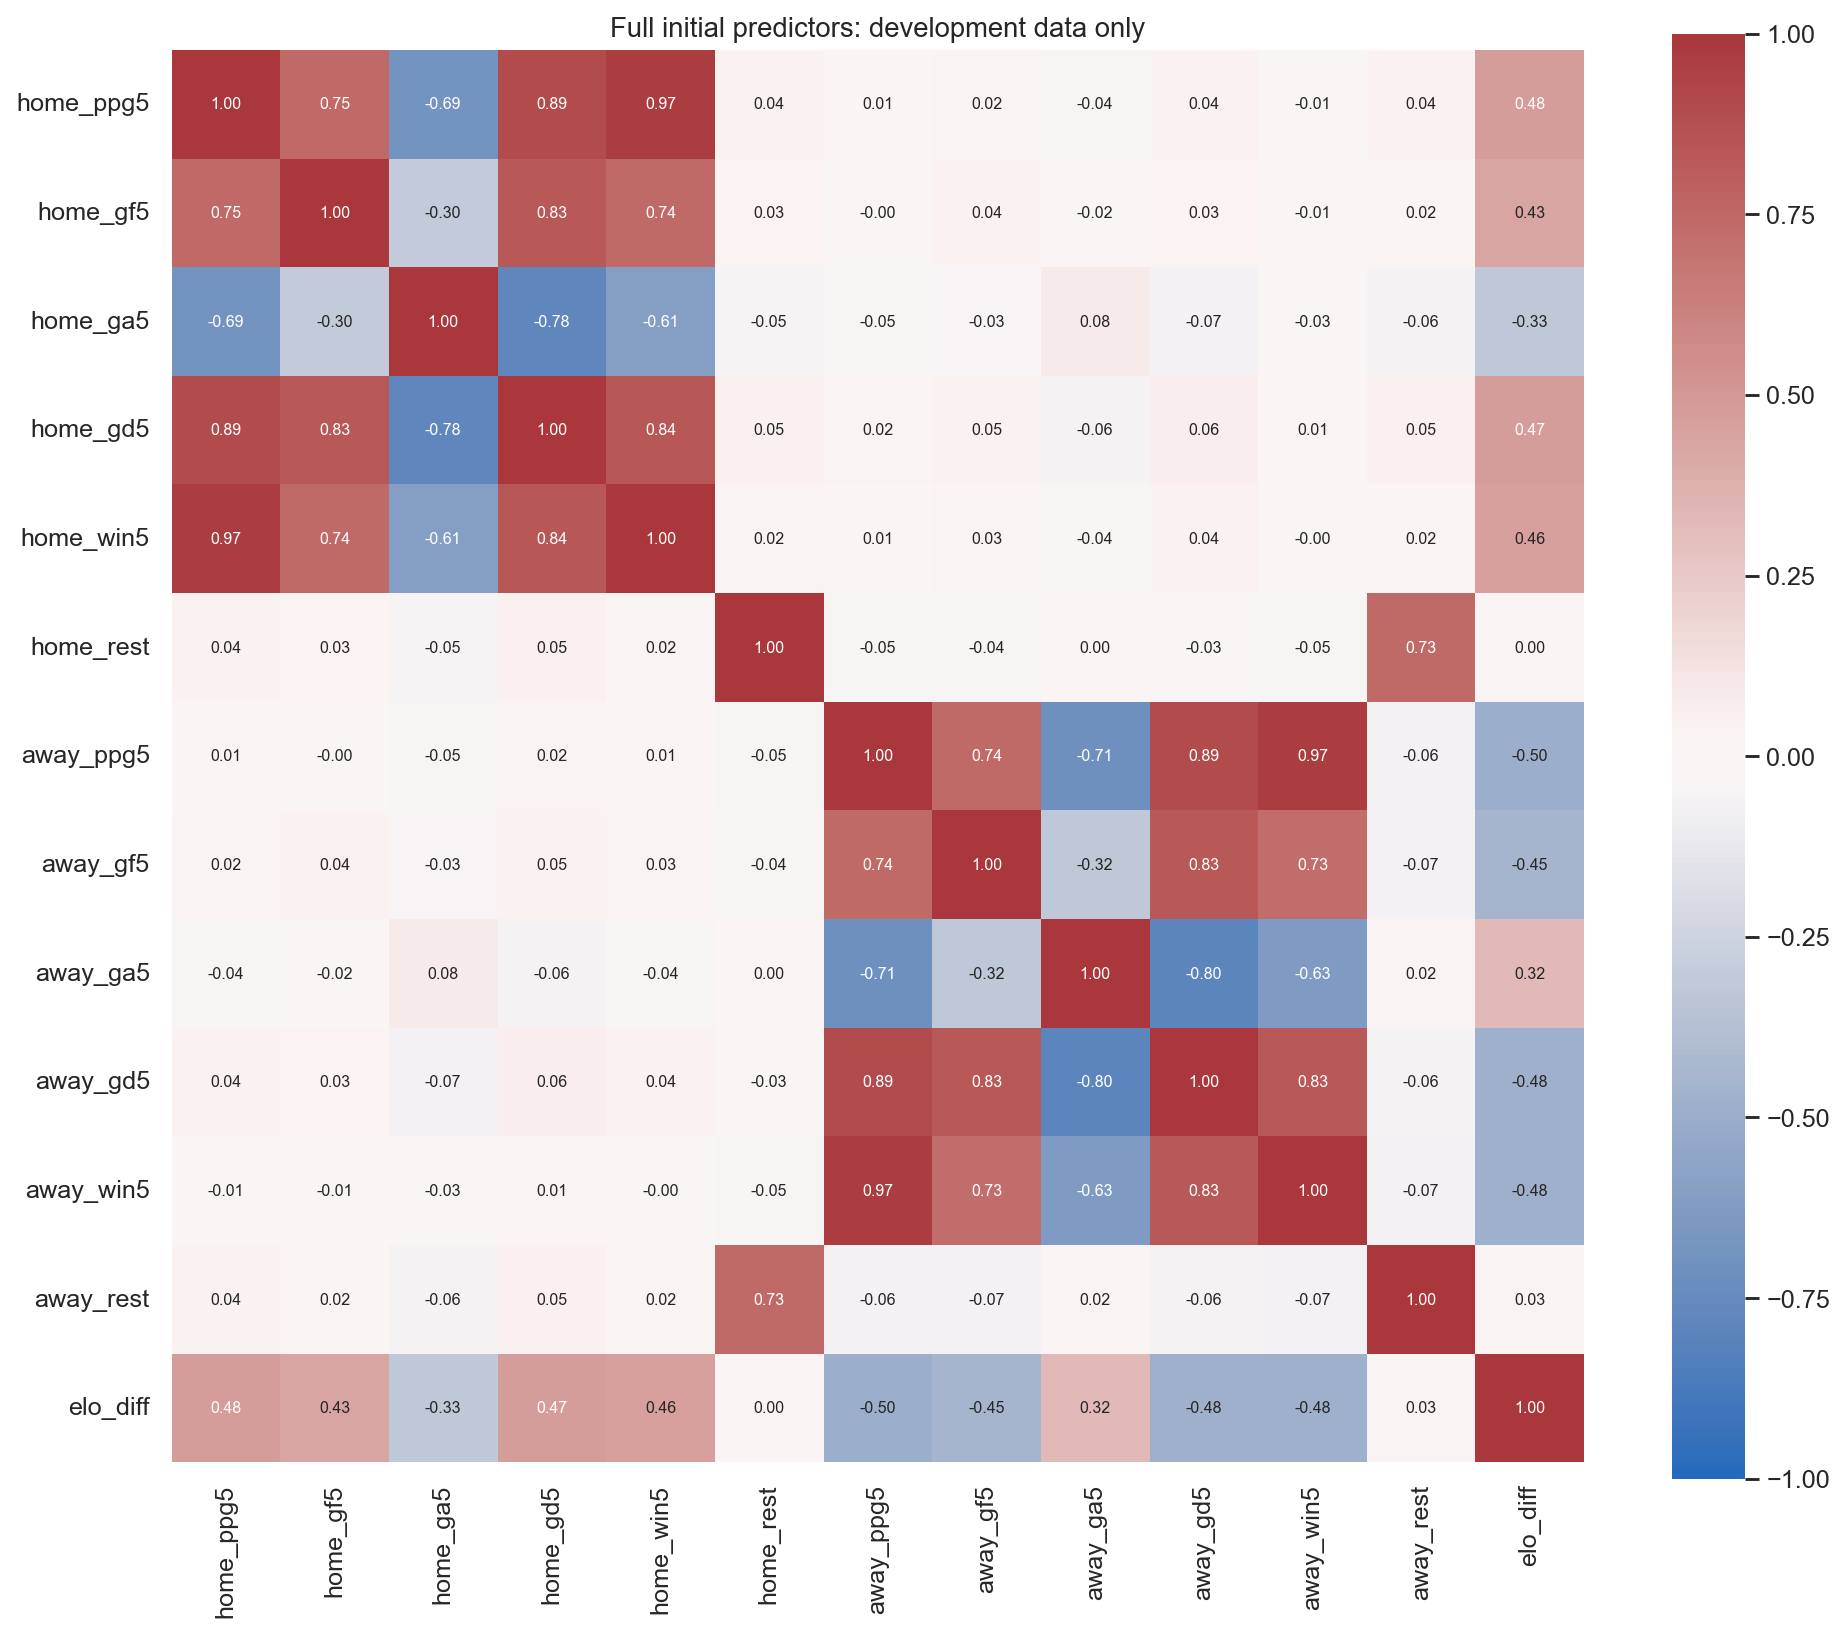

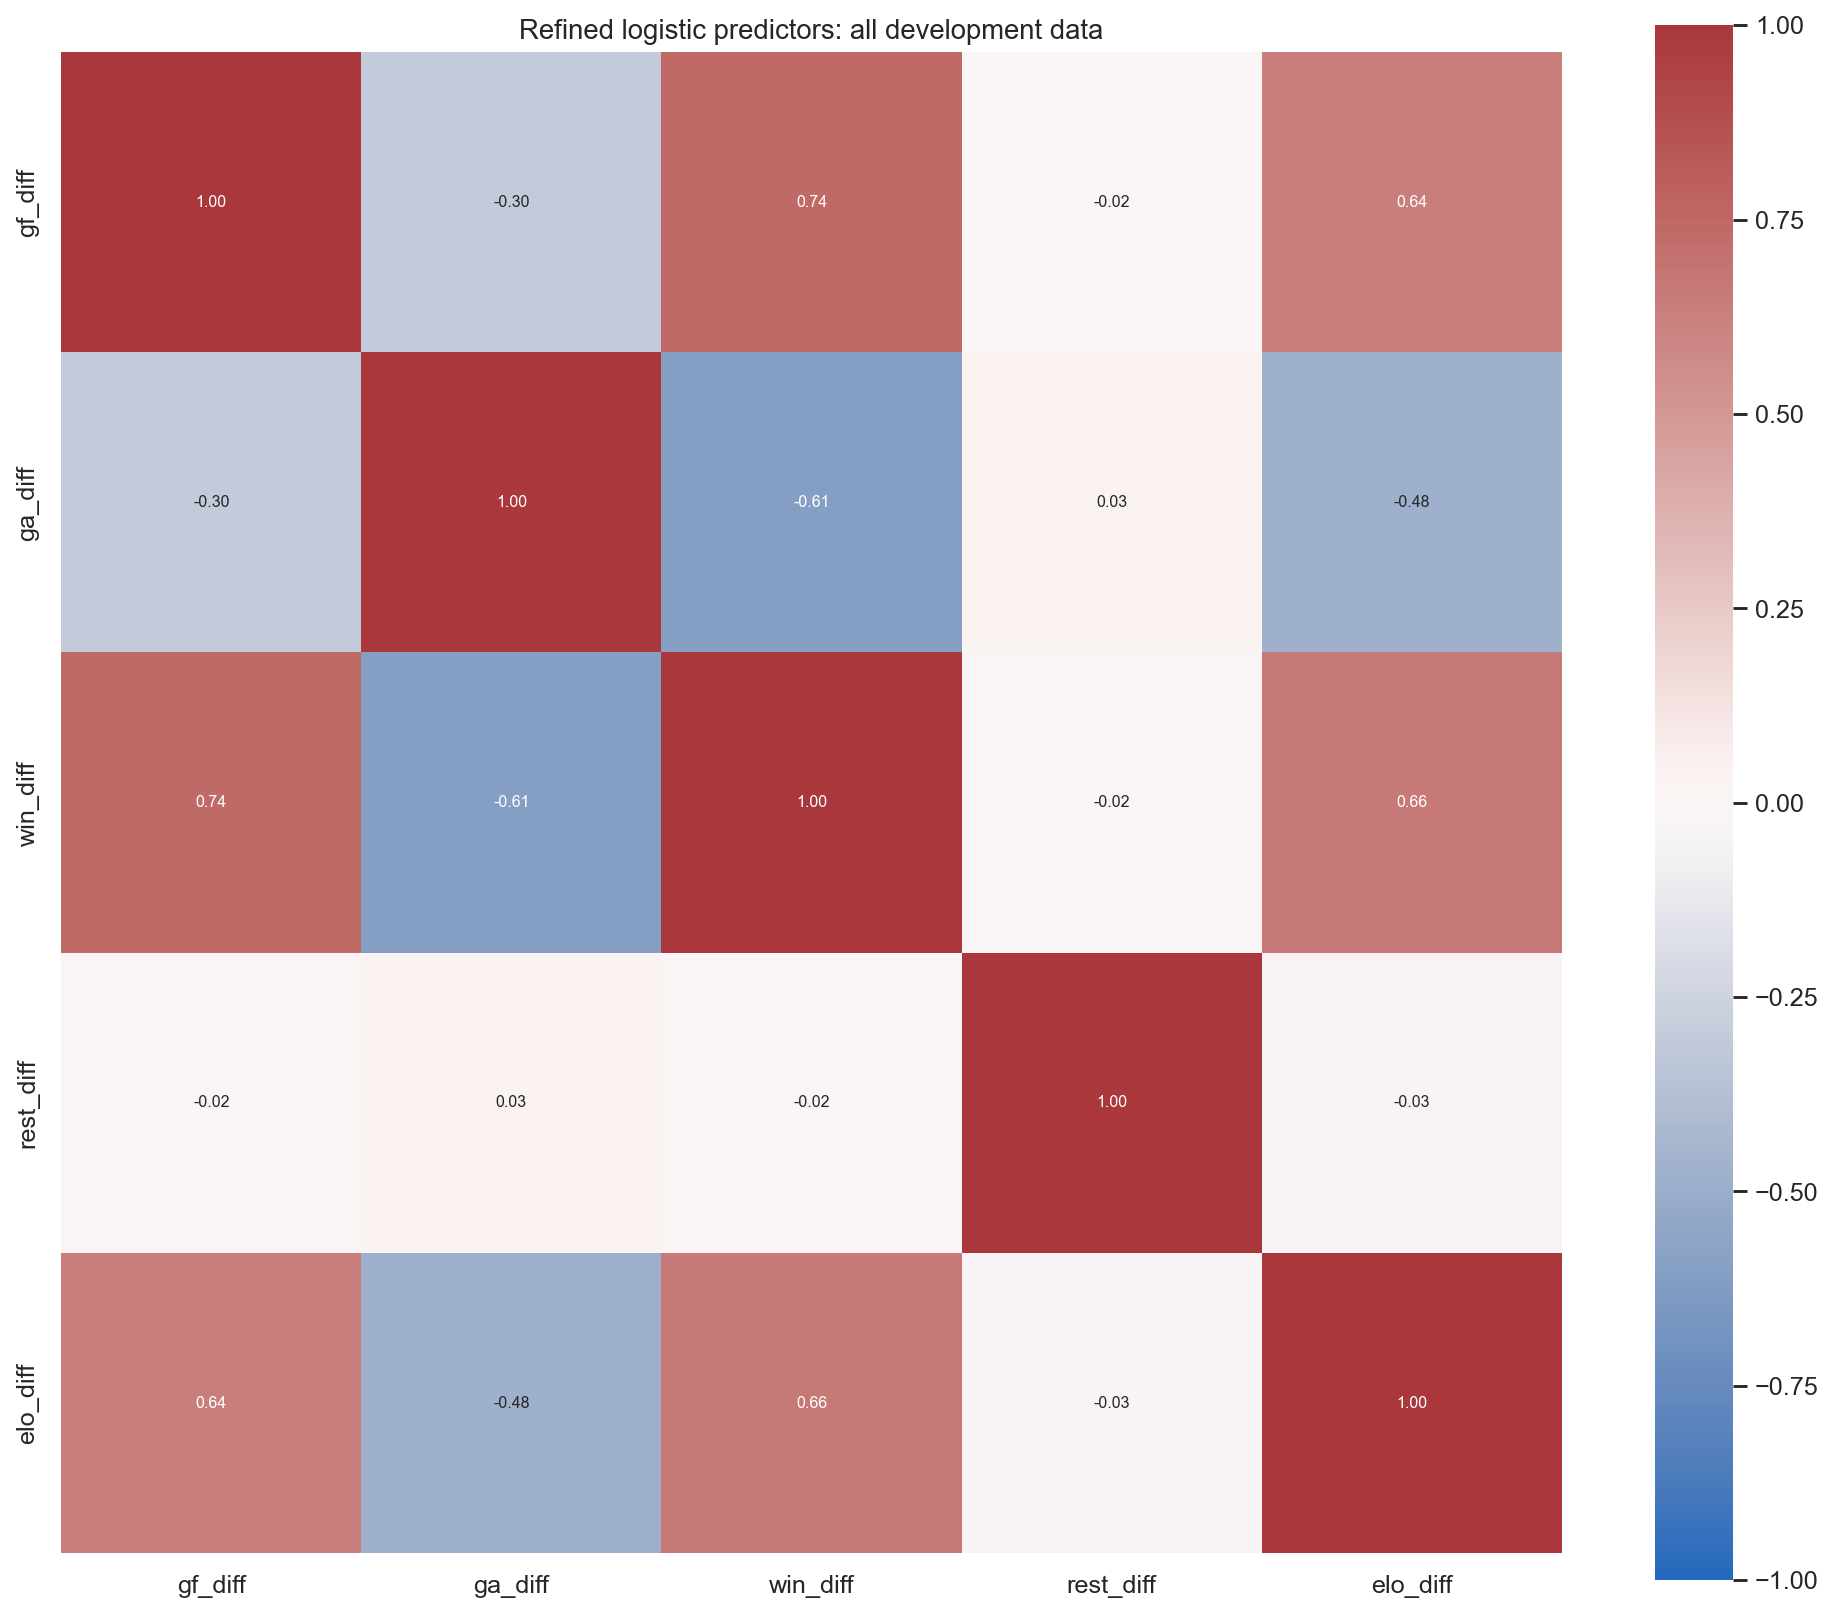

In [3]:
display(Image(filename=str(R/'figures/03_full_correlation.png')))
display(Image(filename=str(R/'figures/09_final_correlation.png')))

## How validation stays honest

Ten expanding chronological folds use strictly earlier dates for training and later dates for validation. Same-day fixtures stay together. The first 266 rows initialize training; 429 distinct later development fixtures receive out-of-fold predictions. Scaling and VIF screening are refitted inside each fold. Model parameters stay fixed within a validation block, while newly observed results may update later pre-match features, exactly as sequential forecasts would.

Nineteen configurations compare majority/prior baselines, initial and refined logistic regression, a class-weighted logistic model, a no-Elo logistic model, decision trees and random forests. The primary selection criterion is pooled out-of-fold multiclass log loss. C controls inverse L2 regularization; tree depth and leaf size control complexity. CV is also used for tuning, so it is not an unbiased nested-CV estimate. The untouched newest complete season supplies the final assessment.

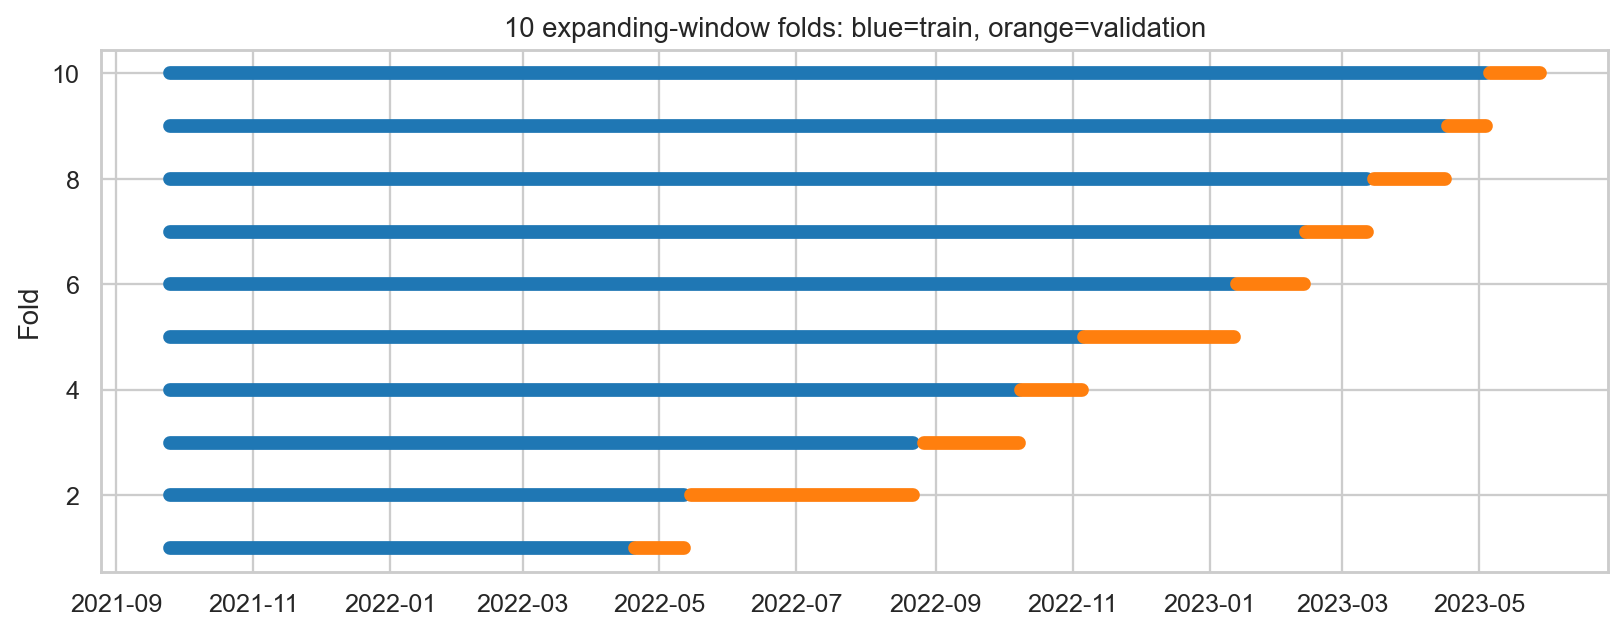

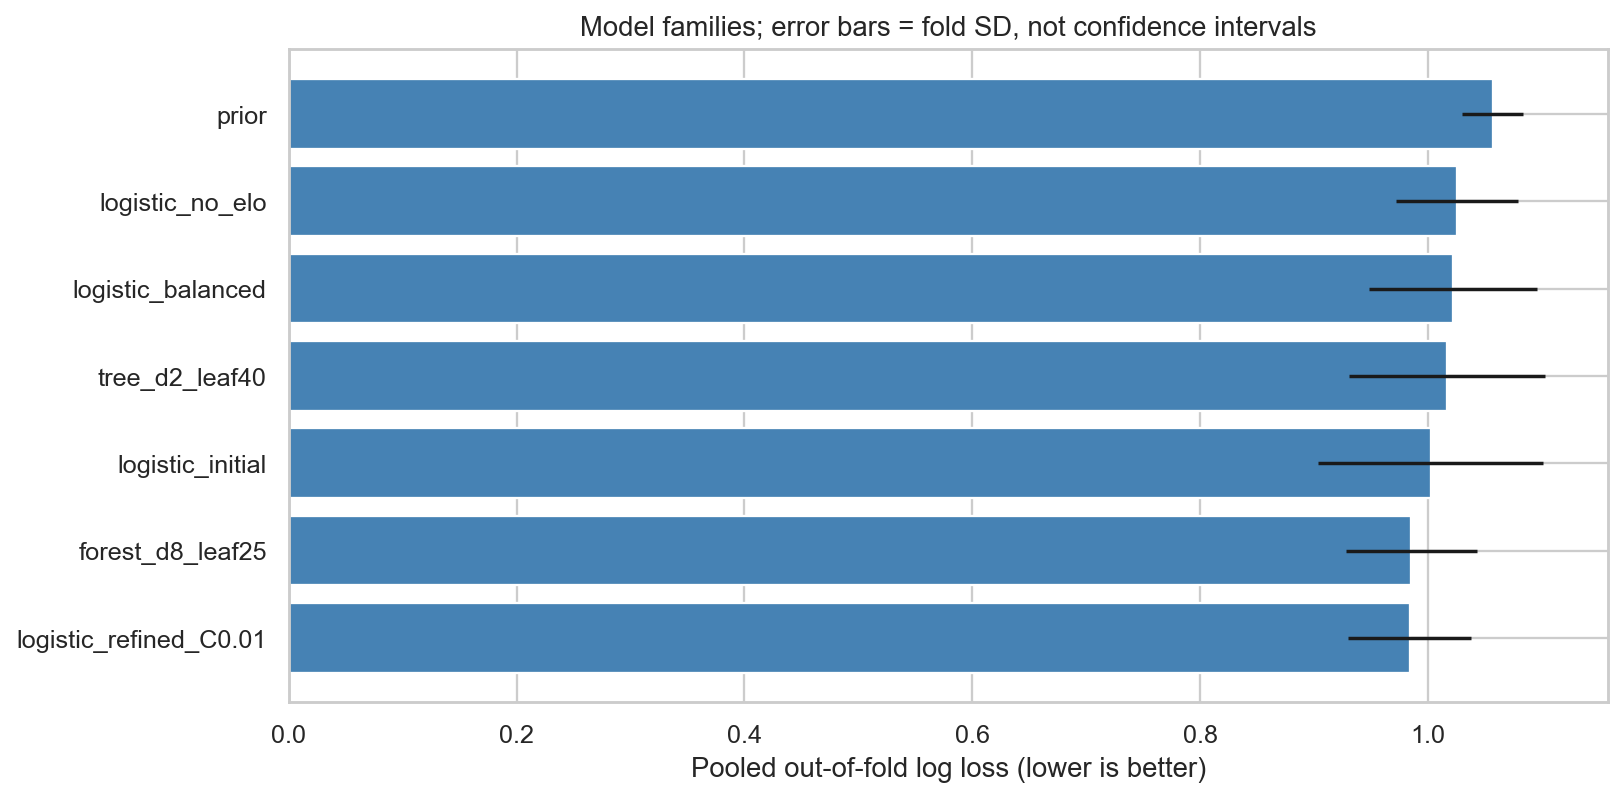

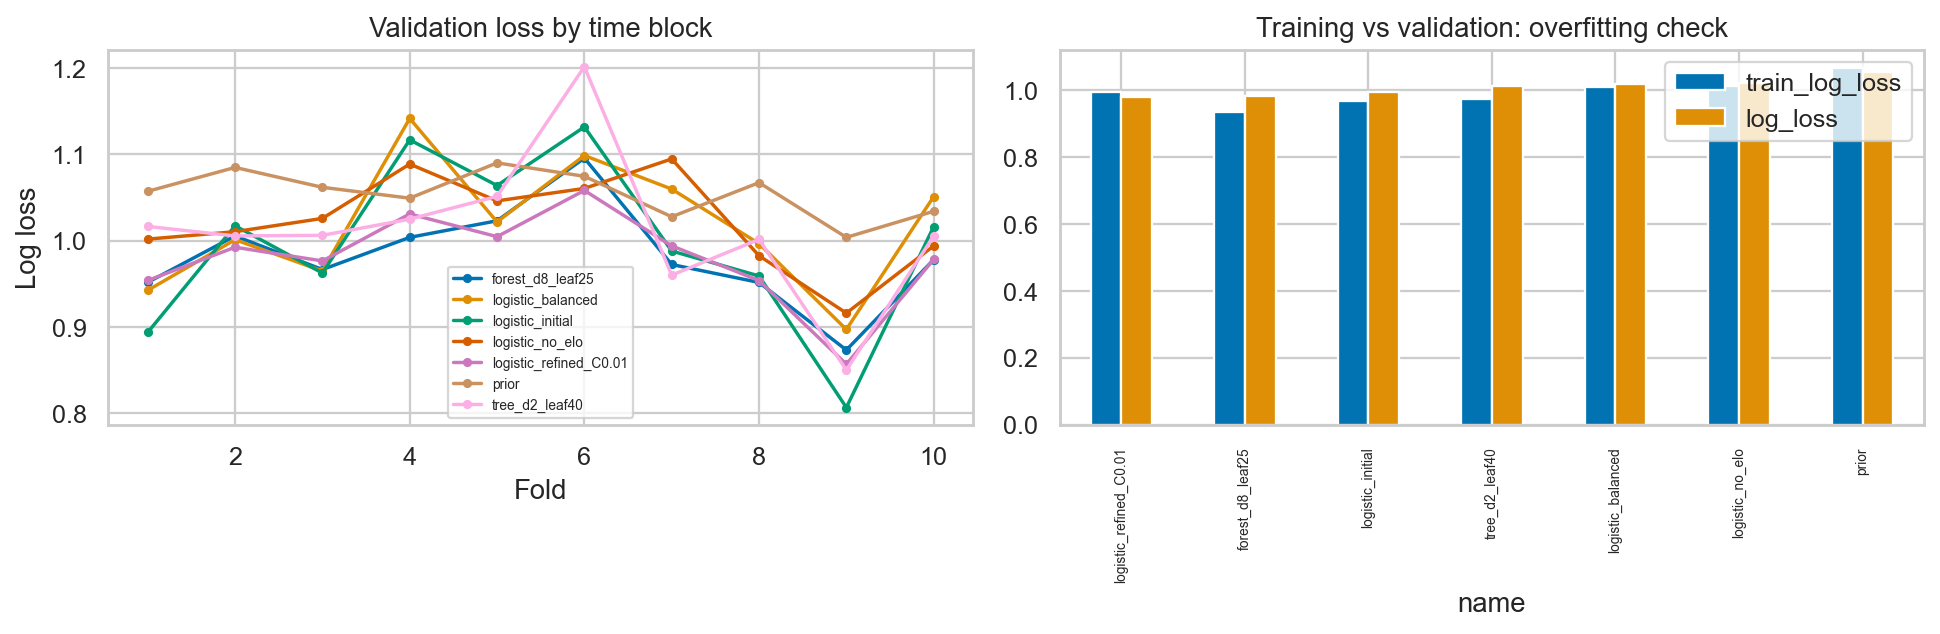

In [4]:
display(Image(filename=str(R/'figures/06_cv_timeline.png')))
display(Image(filename=str(R/'figures/07_model_comparison.png')))
display(Image(filename=str(R/'figures/08_overfitting.png')))

## Diagnostic evidence and refinement decisions

Initial logistic OOF loss was 1.0023; refined logistic loss is 0.9838. This combined change includes difference encoding, VIF screening and stronger regularization; do not attribute all improvement to VIF alone. Refined logistic and forest validation losses differ by only 0.0014, so their ranking is close.

The confusion matrix reveals zero draw recall for the selected OOF model. Its draw probabilities can still be useful even when draw never has the largest probability. Class weighting increases OOF draw recall to 15.3%, but worsens log loss to 1.0219. We keep the probability-focused winner and report the limitation. A different decision objective could justify a different choice, but must be specified before test evaluation.

Calibration and binned probability residuals reveal underprediction of some home-win probabilities and overprediction of some away-win probabilities. The extreme home-win bin has only two OOF examples: do not treat its shape as reliable. We do not fit an extra calibrator to these same OOF results and claim independent improvement. Monthly loss varies, showing that performance is not constant through time. No OLS normal-residual assumption is imposed on a categorical response.

At matched C=0.1, logistic OOF loss is 0.9841 with Elo versus 1.0257 without it. This is evidence for added predictive information in this experiment, not a causal effect.

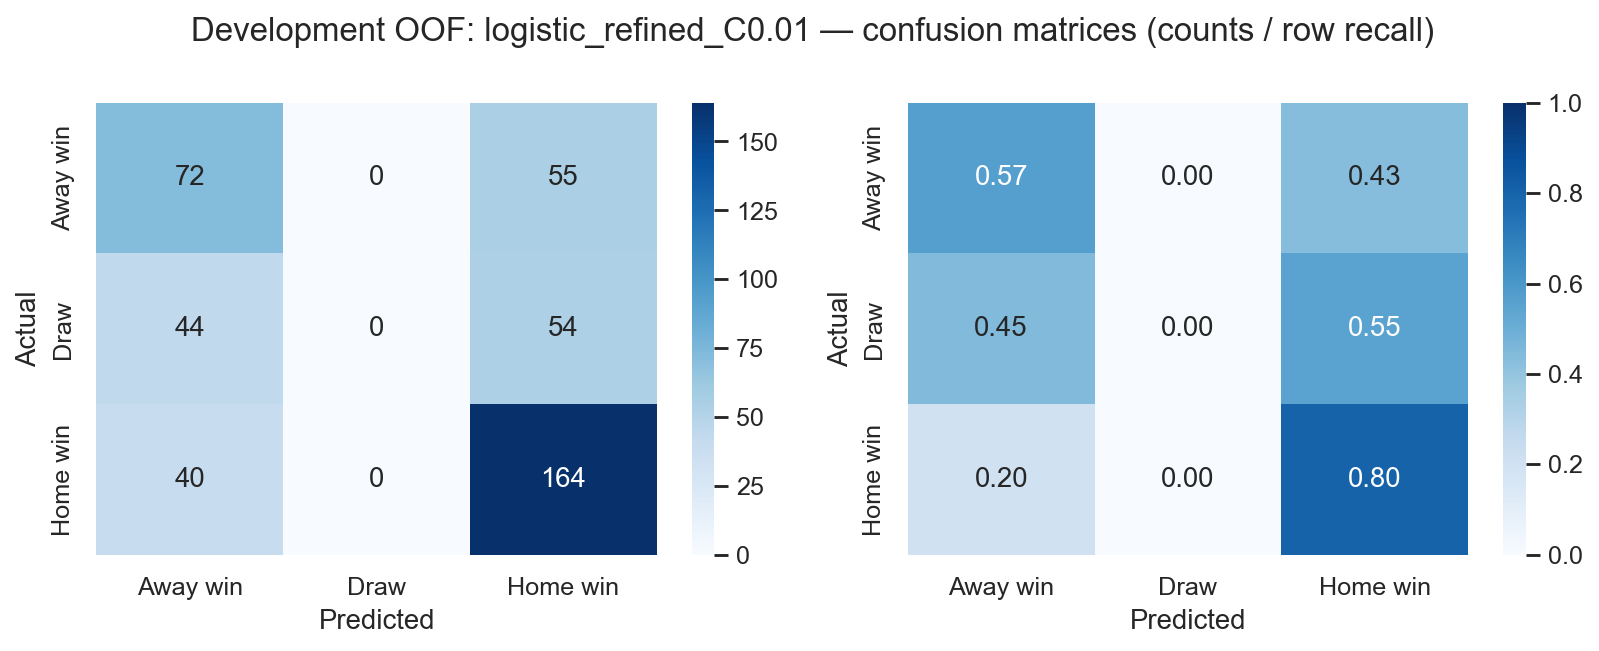

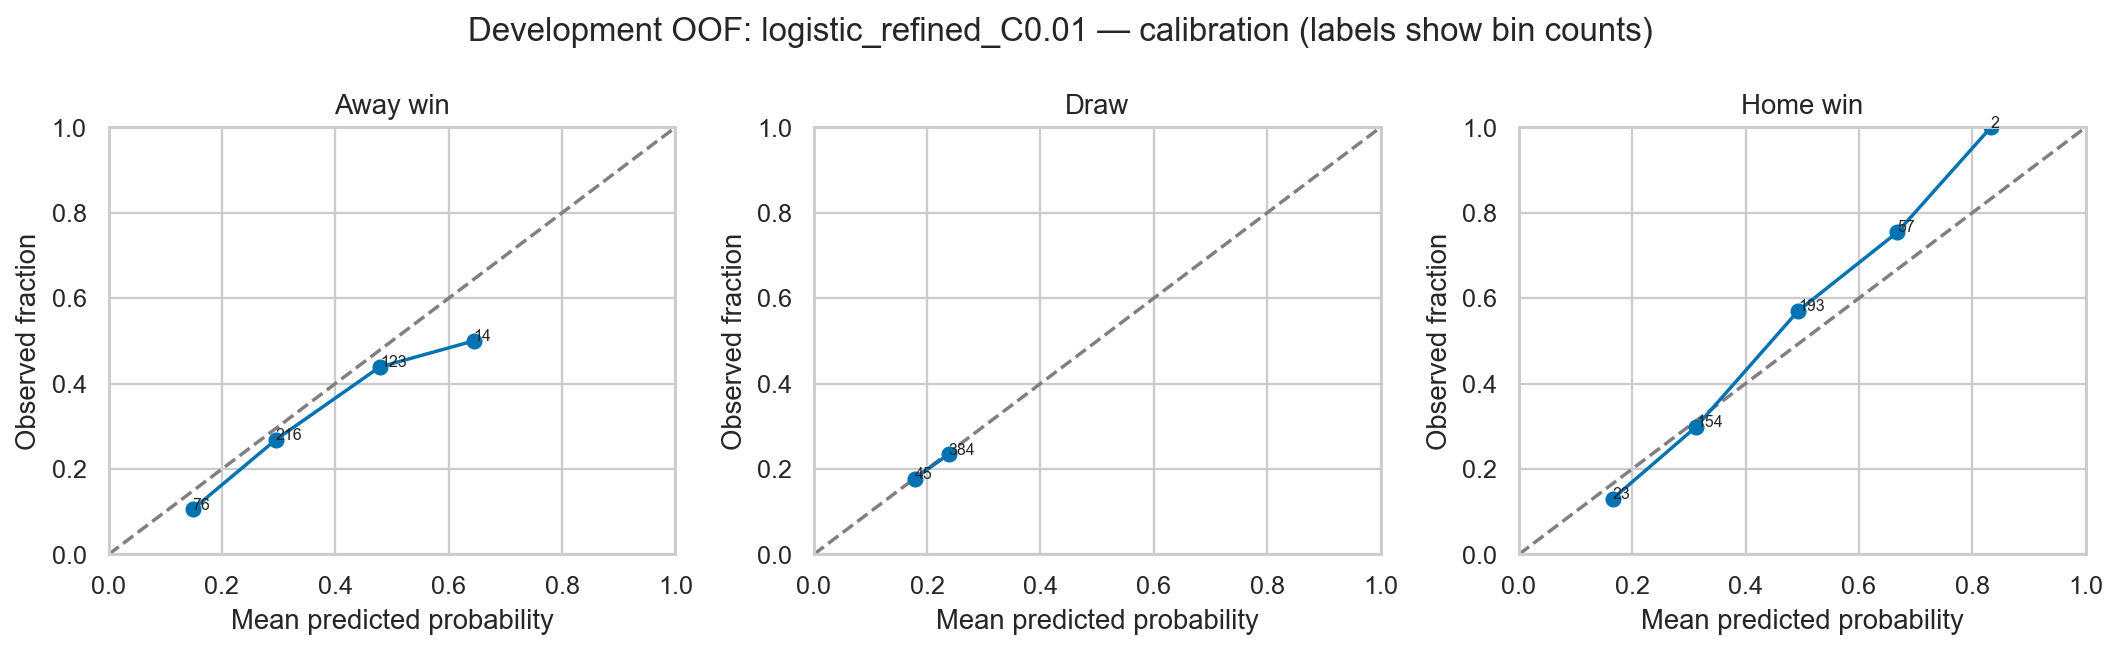

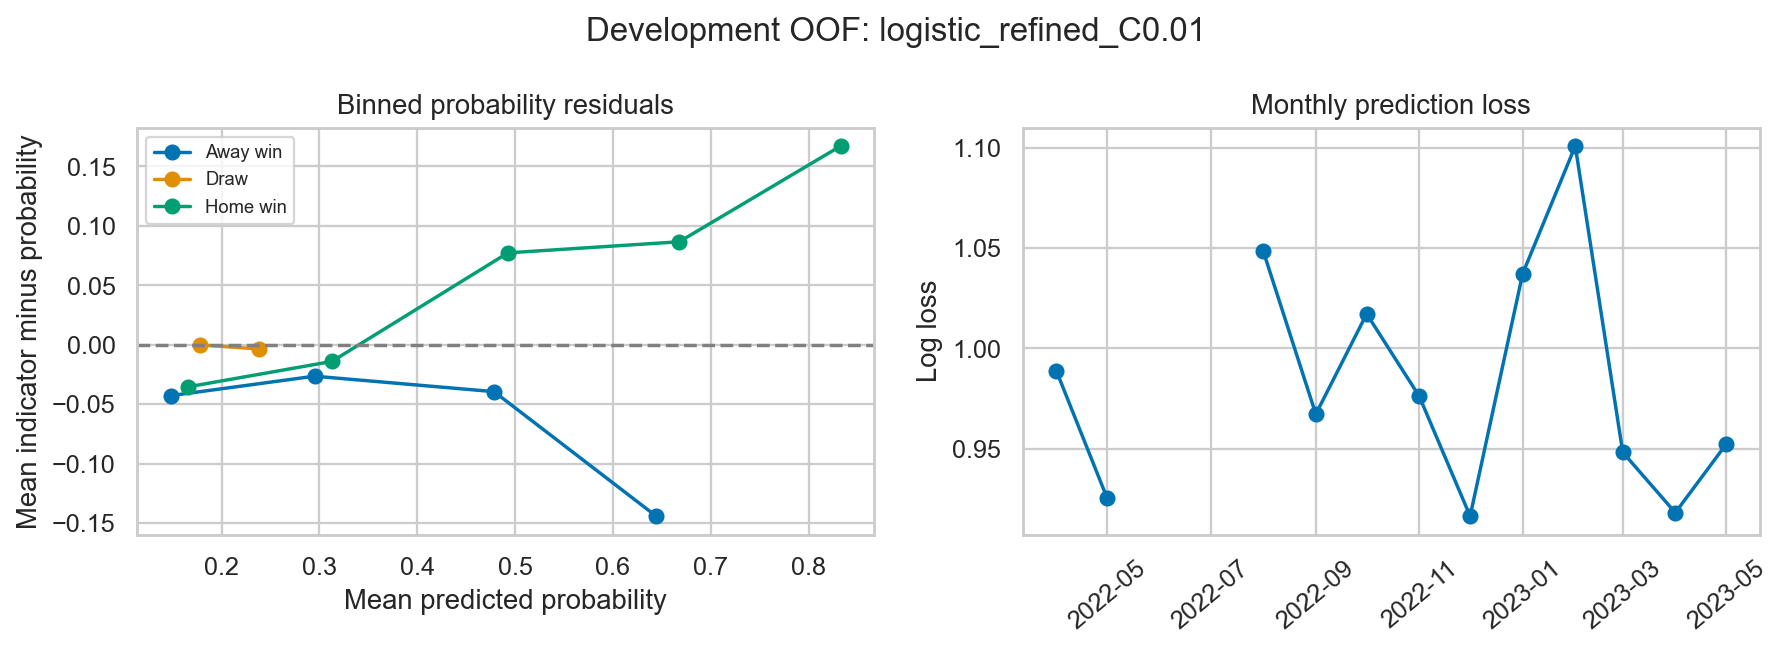

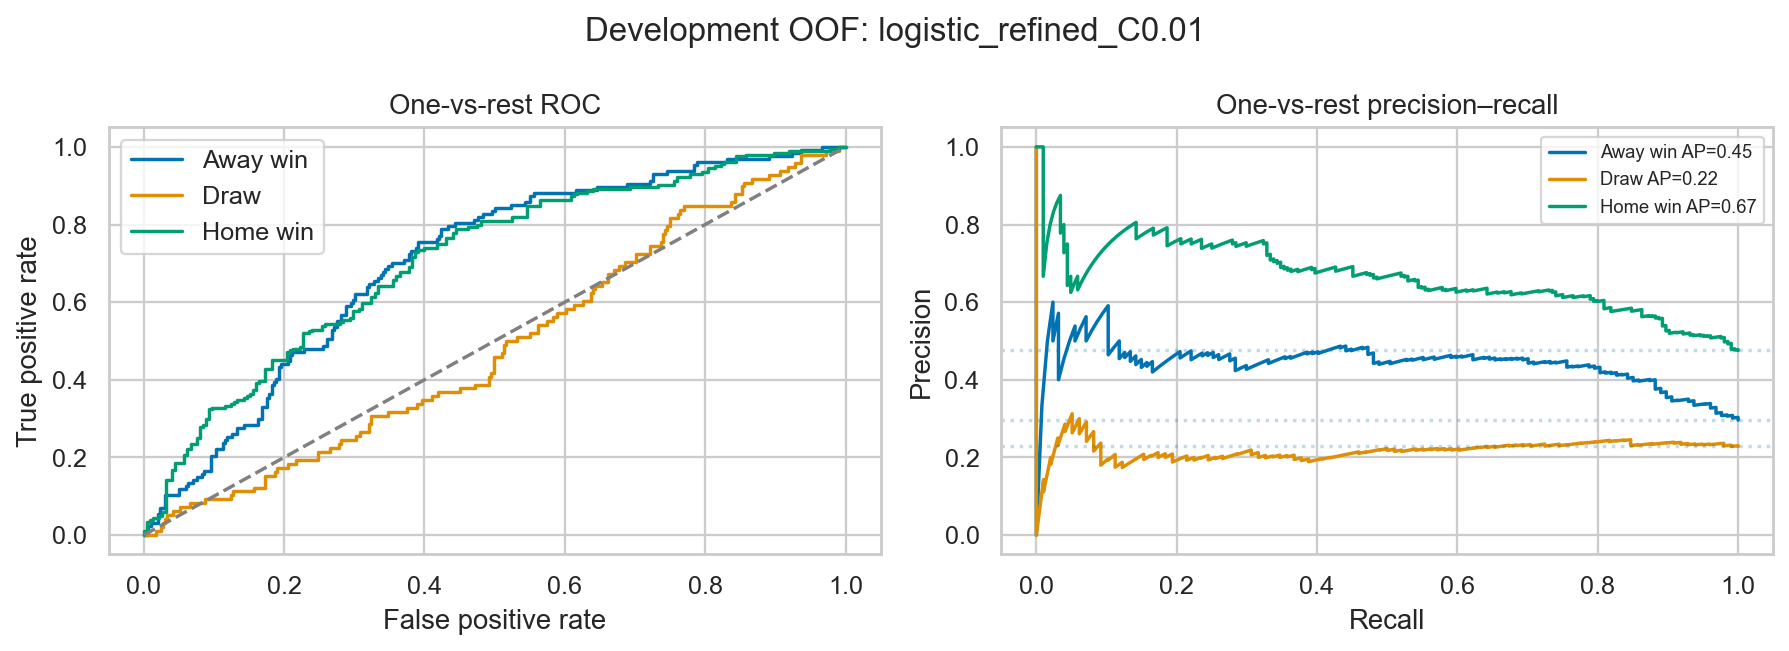

In [5]:
display(Image(filename=str(R/'figures/11_refined_oof_confusion.png')))
display(Image(filename=str(R/'figures/11_refined_oof_calibration.png')))
display(Image(filename=str(R/'figures/11_refined_oof_residuals.png')))
display(Image(filename=str(R/'figures/11_refined_oof_roc_pr.png')))

## Held-out season: no model changes afterward

| Model | CV log loss | Test log loss | Test accuracy | Test macro F1 | Test draw recall |
| --- | --- | --- | --- | --- | --- |
| logistic_refined_C0.01 | 0.9838 | 0.9472 | 0.5649 | 0.4131 | 0.0000 |
| forest_d8_leaf25 | 0.9853 | 0.9667 | 0.5622 | 0.4132 | 0.0000 |
| logistic_initial | 1.0023 | 0.9311 | 0.5676 | 0.4243 | 0.0125 |
| tree_d2_leaf40 | 1.0166 | 0.9961 | 0.5514 | 0.4083 | 0.0000 |
| logistic_balanced | 1.0219 | 0.9798 | 0.5243 | 0.4631 | 0.1625 |
| logistic_no_elo | 1.0257 | 0.9884 | 0.5676 | 0.4113 | 0.0000 |
| prior | 1.0567 | 1.0542 | 0.4595 | 0.2099 | 0.0000 |
| majority | 18.9040 | 19.4831 | 0.4595 | 0.2099 | 0.0000 |

The selected model's macro one-vs-rest AUC is 0.6765, multiclass Brier score is 0.5592, and draw recall is 0.0%. Accuracy should always be shown alongside these class-sensitive and probability metrics. The class-prior baseline accuracy is 45.9%.

Selected-minus-prior mean test log loss is -0.1070. The approximate paired week-block bootstrap 95% interval is [-0.1453, -0.0688]; negative values favor the selected model. Two thousand resamples preserve within-week blocks, but cross-week/team dependence may remain. This is conditional on the fitted models and does not establish a significant logistic-versus-forest difference.

The initial logistic model actually has lower test log loss (0.9311) than the selected refined model (0.9472). It also has slightly higher test accuracy. This is a useful example of validation rankings changing on new data; refinement did not improve every held-out metric. We retain the CV-selected model rather than choosing retrospectively.

The same preselected family representatives are reported for transparency. The selected model is not changed after inspecting this table. All results concern sequential forecasts within 2023–24 using a model fitted through 2022–23, not current 2026 fixtures.

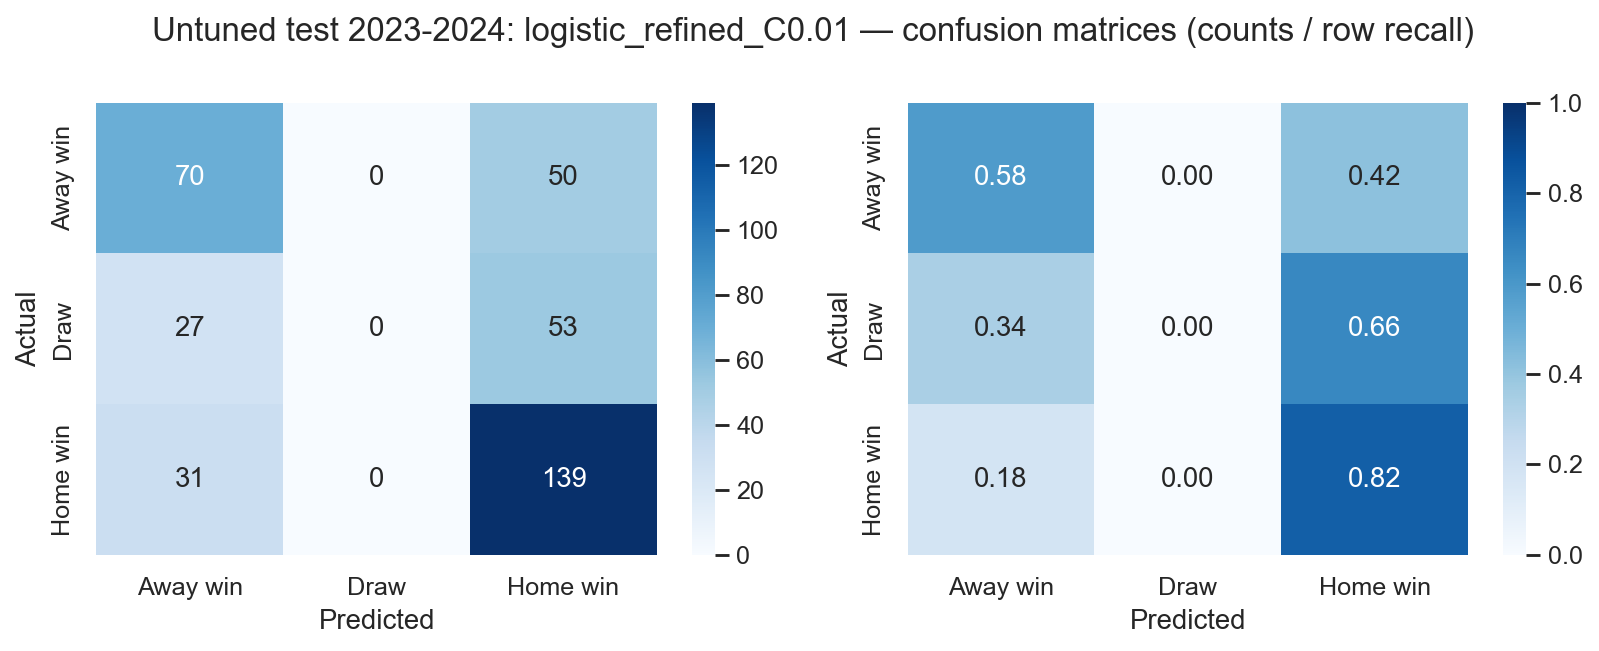

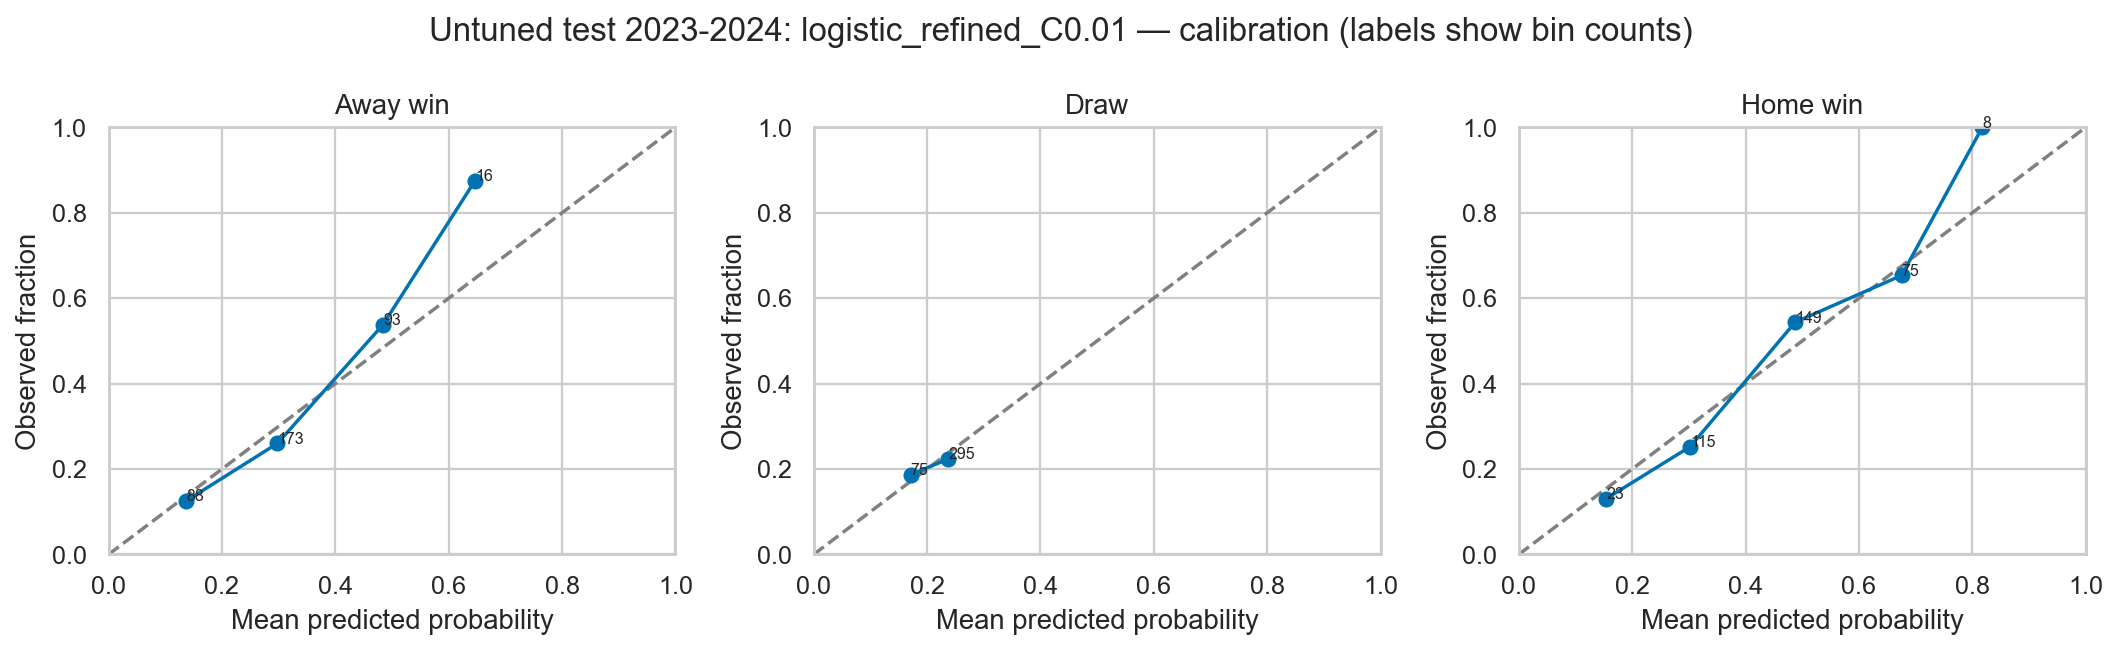

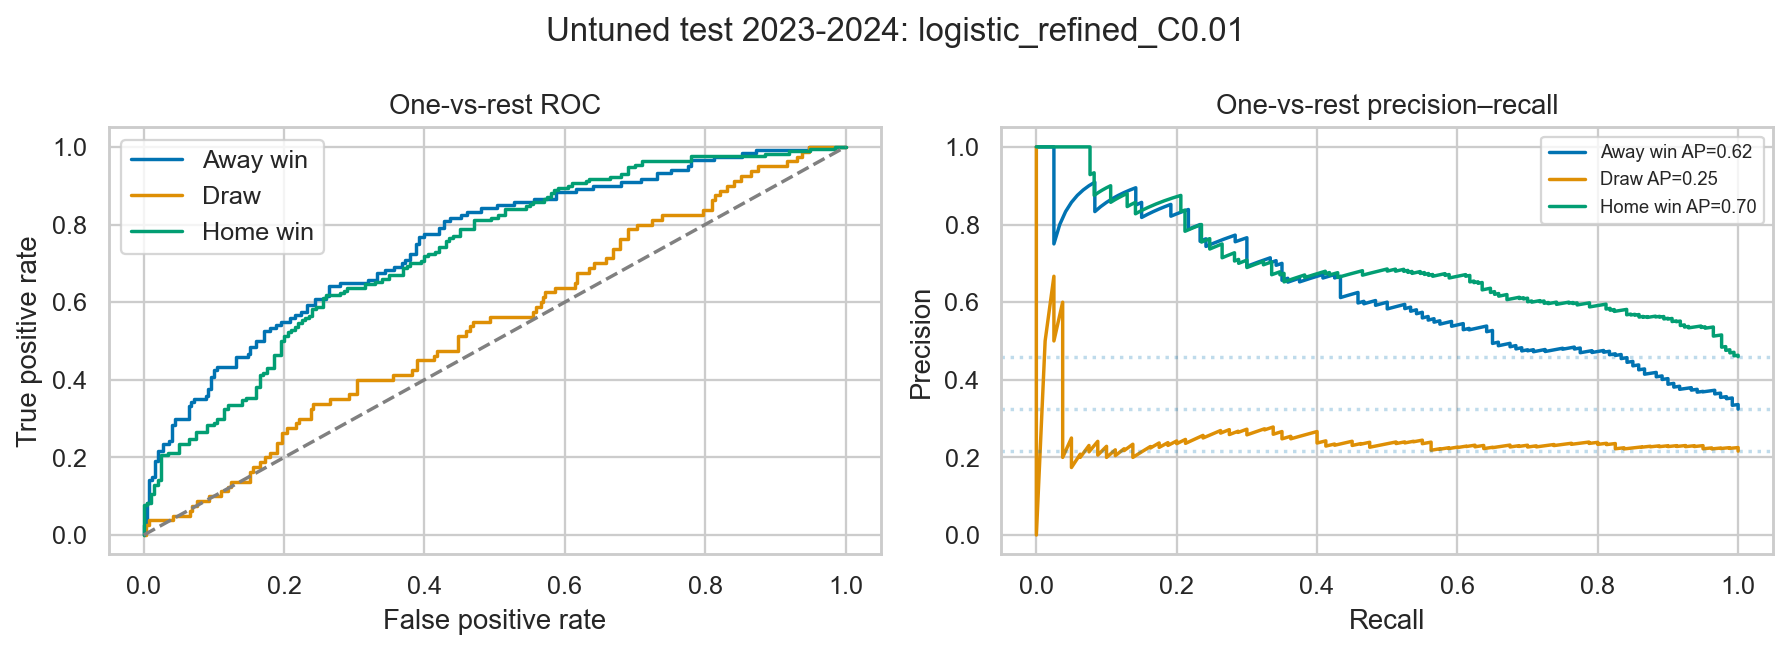

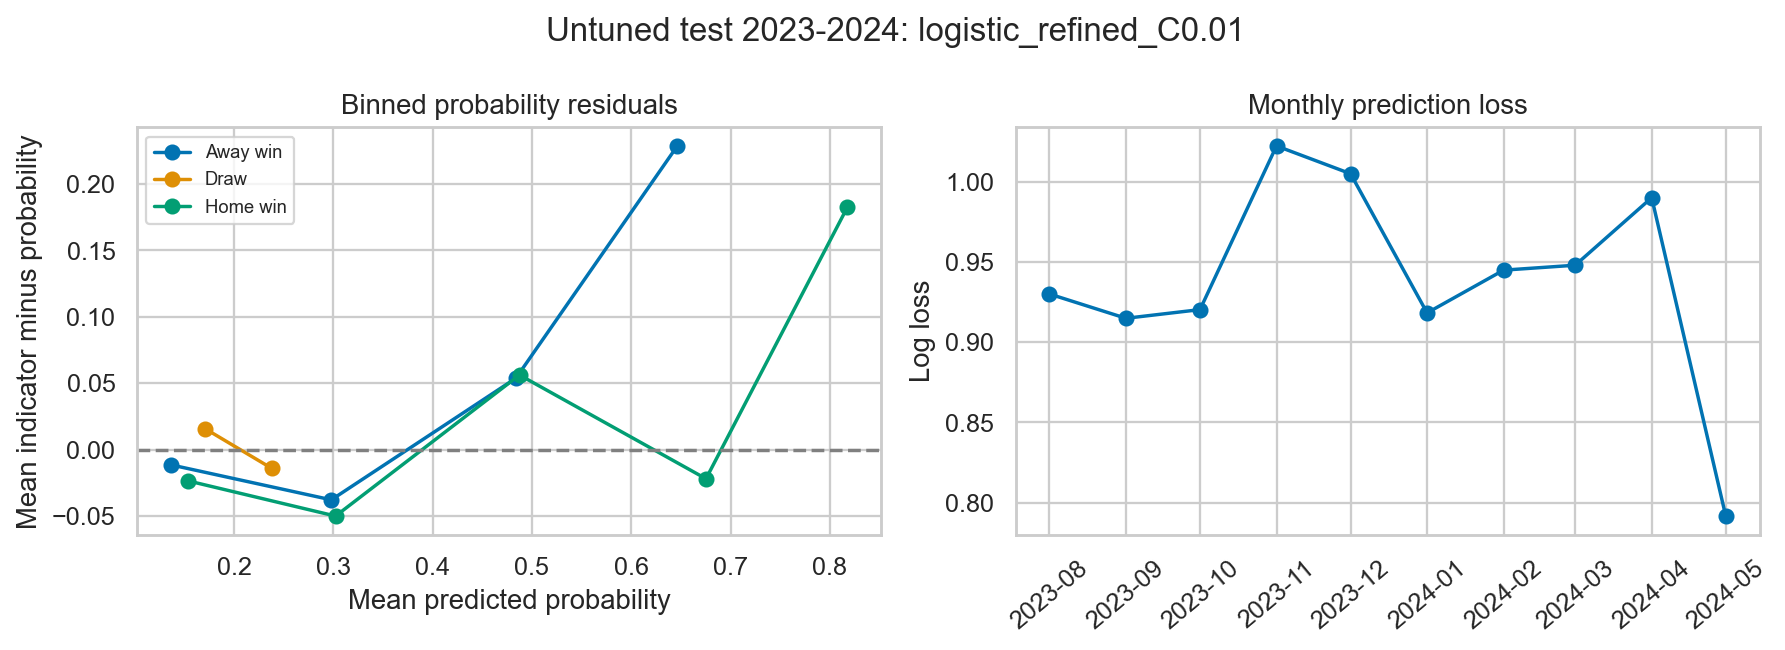

In [6]:
display(Image(filename=str(R/'figures/20_test_confusion.png')))
display(Image(filename=str(R/'figures/20_test_calibration.png')))
display(Image(filename=str(R/'figures/20_test_roc_pr.png')))
display(Image(filename=str(R/'figures/20_test_residuals.png')))

## Interpretation and limits

The coefficient heatmap describes standardized inputs in multinomial logistic regression. To compare home versus away log odds, subtract their coefficients; an individual coefficient is not a percentage-point probability effect. The shallow decision tree illustrates nonlinear rules; its thresholds are on standardized values.

Repeated teams, one test season, stale historical data, promoted-team warm-up exclusions, narrow draw probabilities and absent lineup/injury/transfer information limit generalization. Valid surprises are not deleted. Further improvements require fresh independent seasons, not repeated tuning on this test season.

The original Flask pages and saved pickles are retained as legacy work, not the evaluated model. Use the new historical prediction command for the demonstration. It rejects unsupported future dates. See docs/METHODOLOGY.md, docs/COURSE_ALIGNMENT.md and docs/TEAM_PRESENTATION.md for details and rehearsal questions.

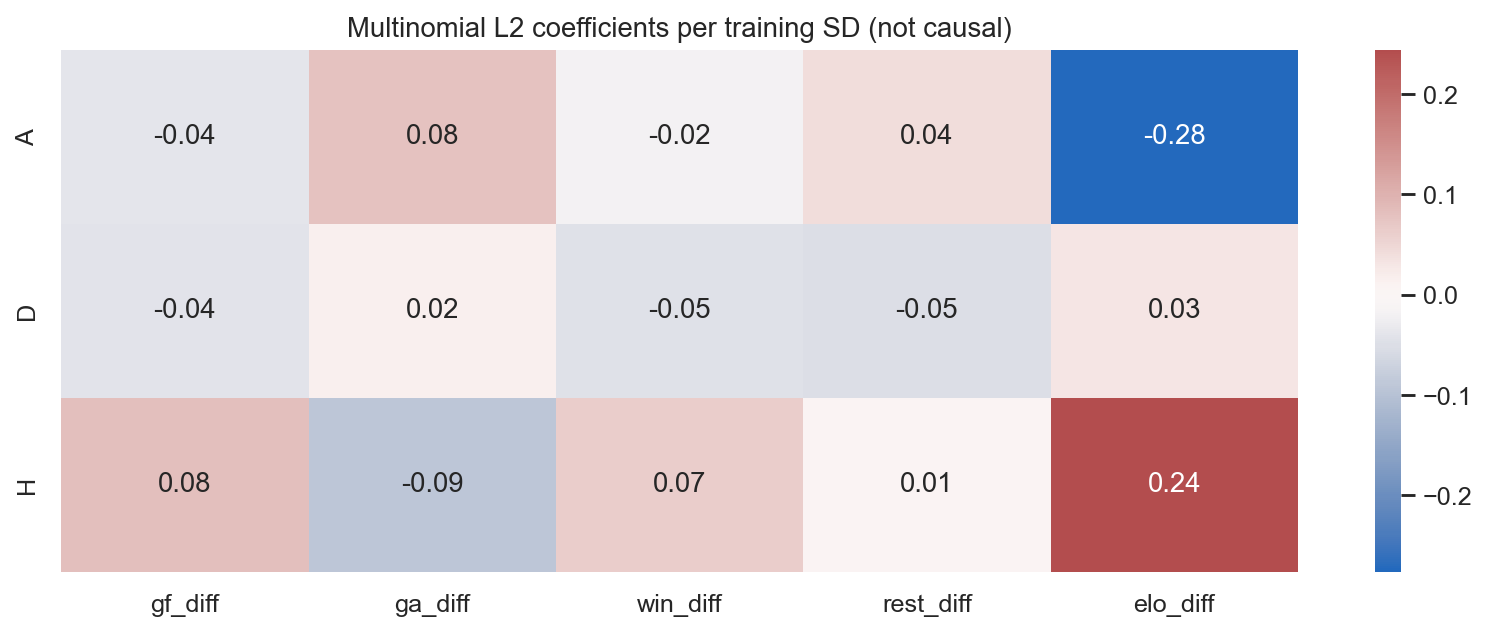

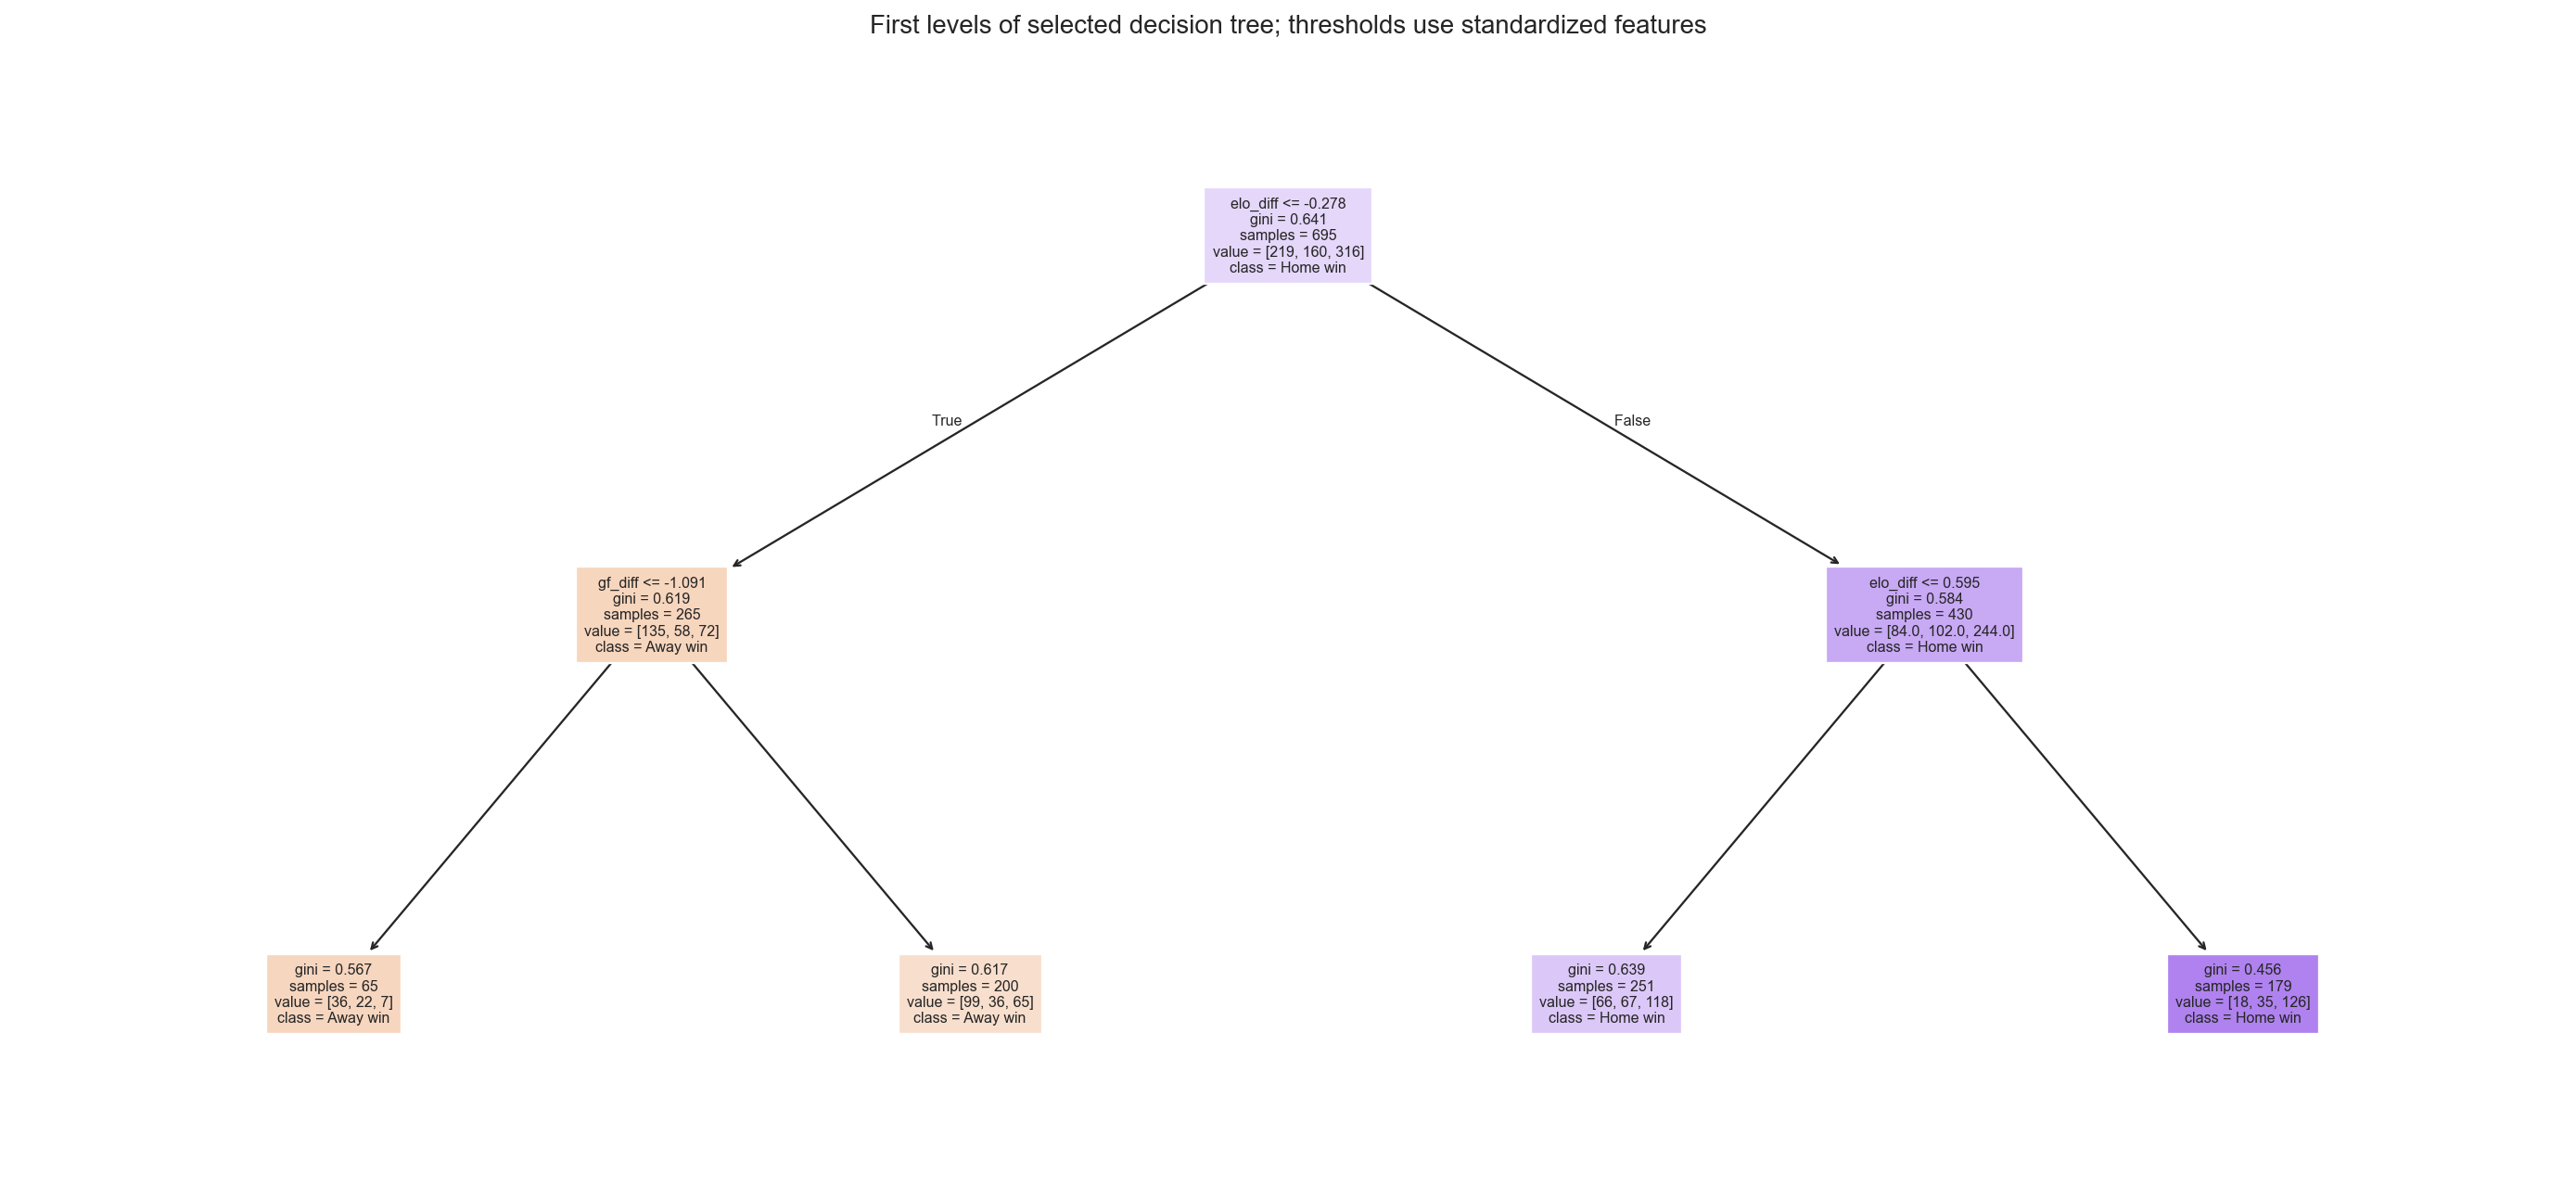

In [7]:
display(Image(filename=str(R/'figures/15_logistic_coefficients.png')))
display(Image(filename=str(R/'figures/16_tree.png')))

In [8]:
display(pd.read_csv(R/'cleaning_audit.csv'))
display(pd.read_csv(R/'cv_splits.csv'))
display(pd.read_csv(R/'cv_summary.csv'))
display(pd.read_csv(R/'test_metrics.csv'))
display(pd.read_csv(R/'final_development_vif.csv'))

,step,remaining,removed
0,cached records,1520,0
1,Premier League only,1520,0
2,remove identical repeated match IDs,1520,0
3,completed matches only,1359,161
4,"valid dates, teams and scores",1359,0
5,valid opponents and integer nonnegative scores,1359,0
6,complete 380-match seasons only,1140,219


,fold,train_n,validation_n,train_end,validation_start,validation_end
0,1,266,42,2022-04-19,2022-04-20,2022-05-12
1,2,308,43,2022-05-12,2022-05-15,2022-08-22
2,3,351,46,2022-08-22,2022-08-27,2022-10-08
3,4,397,49,2022-10-08,2022-10-09,2022-11-05
4,5,446,46,2022-11-05,2022-11-06,2023-01-12
5,6,492,42,2023-01-12,2023-01-13,2023-02-12
6,7,534,42,2023-02-12,2023-02-13,2023-03-12
7,8,576,44,2023-03-12,2023-03-15,2023-04-16
8,9,620,32,2023-04-16,2023-04-17,2023-05-04
9,10,652,43,2023-05-04,2023-05-06,2023-05-28


,name,family,cv_accuracy,cv_macro_f1,cv_balanced_accuracy,cv_log_loss,cv_brier_multiclass,cv_draw_recall,cv_auc_macro_ovr,fold_log_loss_sd
0,logistic_refined_C0.01,logistic_refined,0.550117,0.398822,0.456950,0.983837,0.586632,0.000000,0.633255,0.053984
1,logistic_refined_C0.1,logistic_refined,0.543124,0.399040,0.457992,0.984054,0.587341,0.000000,0.637419,0.079393
2,forest_d8_leaf25,random_forest,0.547786,0.398936,0.457298,0.985260,0.587395,0.000000,0.644335,0.057390
3,forest_d4_leaf25,random_forest,0.545455,0.396725,0.454673,0.985285,0.587409,0.000000,0.642722,0.057416
4,forest_d4_leaf10,random_forest,0.547786,0.396580,0.454326,0.987701,0.588723,0.000000,0.643950,0.066816
5,logistic_refined_C1,logistic_refined,0.538462,0.407503,0.457268,0.990483,0.591160,0.020408,0.637226,0.089718
6,logistic_refined_C10,logistic_refined,0.538462,0.407503,0.457268,0.991640,0.591829,0.020408,0.637067,0.091105
7,forest_d8_leaf10,random_forest,0.538462,0.410349,0.455073,0.995483,0.593591,0.030612,0.643776,0.075046
8,logistic_initial,logistic_initial,0.540793,0.399395,0.456358,1.002319,0.596978,0.000000,0.627194,0.098530
9,tree_d2_leaf40,decision_tree,0.545455,0.396176,0.452692,1.016588,0.606736,0.000000,0.610432,0.086167


,name,selected_by_cv,accuracy,macro_f1,balanced_accuracy,log_loss,brier_multiclass,draw_recall,auc_macro_ovr
0,logistic_refined_C0.01,True,0.564865,0.413091,0.466993,0.947207,0.559161,0.0000,0.676540
1,forest_d8_leaf25,False,0.562162,0.413152,0.469118,0.966673,0.571974,0.0000,0.654482
2,logistic_initial,False,0.567568,0.424321,0.474428,0.931148,0.548336,0.0125,0.692013
3,tree_d2_leaf40,False,0.551351,0.408319,0.466176,0.996126,0.588454,0.0000,0.620536
4,logistic_balanced,False,0.524324,0.463055,0.472794,0.979752,0.581808,0.1625,0.672133
5,logistic_no_elo,False,0.567568,0.411322,0.464052,0.988434,0.588073,0.0000,0.640356
6,prior,False,0.459459,0.209877,0.333333,1.054240,0.637265,0.0000,0.500000
7,majority,False,0.459459,0.209877,0.333333,19.483056,1.081081,0.0000,0.500000


,feature,vif
0,gf_diff,2.673764
1,ga_diff,1.795446
2,win_diff,3.506291
3,rest_diff,1.001719
4,elo_diff,2.054513


## Historical matchup demonstration
An archived hypothetical matchup, not a live 2026 forecast. All history predates the selected date.

In [9]:
from analysis.predict import predict_match
predict_match('Arsenal','Chelsea','2024-05-20')

{'home': 'Arsenal',
 'away': 'Chelsea',
 'date': '2024-05-20',
 'model': 'logistic_refined_C0.01',
 'probabilities': {'Away win': 0.17992688474254553,
  'Draw': 0.22397229968430635,
  'Home win': 0.5961008155731481},
 'most_likely': 'Home win',
 'notice': 'Archived-data demonstration; hypothetical fixture, not a current live prediction. No lineups, injuries or betting odds.'}